# Pseudotime trajectories

Epione ports ArchR's supervised trajectory analysis:

| ArchR | Epione |
|---|---|
| `addTrajectory` | `epi.tl.add_trajectory` |
| `getTrajectory` | `epi.tl.get_trajectory` |
| `plotTrajectoryHeatmap` / `trajectoryHeatmap` | `epi.pl.plot_trajectory_heatmap`, `epi.tl.trajectory_heatmap_matrix` (= `returnMatrix = TRUE`) |
| `correlateTrajectories` | `epi.tl.correlate_trajectories` |
| `plotTrajectory` | `epi.pl.plot_trajectory` |

**How a supervised trajectory is fitted.** You give an ordered list of cell groups
(here progenitor → GMP → monocyte). Within each group, cells further than the 90th distance
quantile from the group centroid are dropped; every remaining cell gets an
*initial time* `x + (1 - q)` (distance quantile to the next group's centroid; the
last group uses the previous centroid). For each dimension of the reduced space a
cubic smoothing spline (`stats::smooth.spline(spar = 1)`) is fitted against this
time, giving a curve through the space. Every cell is then projected onto its
nearest spline points (k = 3), and the rank of that position becomes the
pseudo-time in `(0, 100]`. Epione re-implements `smooth.spline` itself, so the
spline agrees with R to ~1e-10.

We use the **ArchR Hematopoiesis tutorial data** (BMMC + CD34⁺ BMMC + PBMC, about 10,700
cells), preprocessed entirely with Epione in {doc}`t_archr_heme_data`: iterative LSI, UMAP,
Leiden `Clusters`, gene scores and chromVAR deviations of JASPAR2020 motifs.

In [1]:
%matplotlib inline
import os, pathlib
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt
from IPython.display import display

import epione as epi

# Folder written by the t_archr_heme_data tutorial.
DATA = pathlib.Path(os.environ.get('EPIONE_ARCHR_HEME', 'data_archr_heme'))

## Load the data

`heme_gene_scores.h5ad` holds the gene scores (`epi.tl.add_gene_score_matrix`) together with
the cell metadata, the 30-dimensional iterative LSI (`obsm['X_iterative_lsi']`) and the UMAP
(`obsm['X_umap']`).

In [2]:
adata = ad.read_h5ad(DATA / 'heme_gene_scores.h5ad')
adata.var_names_make_unique()
adata.var['name'] = adata.var_names.astype(str)
adata.obs['Clusters'] = adata.obs['Clusters'].astype(str)
adata

AnnData object with n_obs × n_vars = 10705 × 20057
    obs: 'Sample', 'n_fragment', 'tsse', 'Clusters'
    var: 'chrom', 'start', 'end', 'strand', 'name'
    uns: 'files'
    obsm: 'X_iterative_lsi', 'X_umap'

## Choose the trajectory groups

A supervised trajectory needs an ordered list of cell groups. We pick them from the mean gene
score of lineage markers per cluster: the cluster with the strongest progenitor signature
(CD34, CRHBP), then the strongest GMP signature (MPO, ELANE) and the strongest monocyte
signature (CD14, LYZ, CEBPB) among the remaining clusters. This is the myeloid branch of the
ArchR tutorial.

progenitor -> C4  (signature z = 1.65)
GMP        -> C3  (signature z = 2.25)
monocyte   -> C1  (signature z = 2.66)
trajectory: C4 -> C3 -> C1


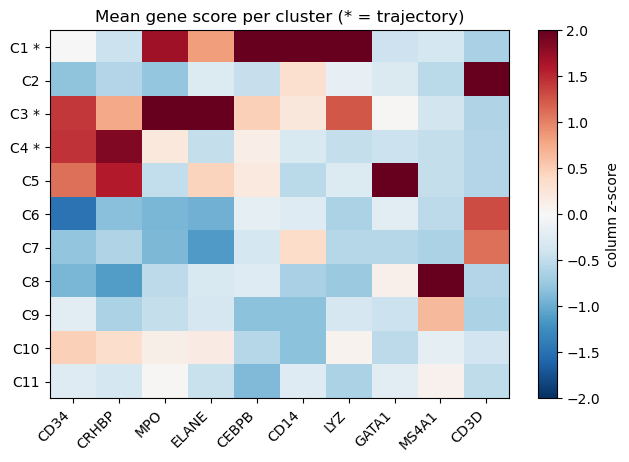

In [3]:
markers = ['CD34', 'CRHBP', 'MPO', 'ELANE', 'CEBPB', 'CD14', 'LYZ', 'GATA1', 'MS4A1', 'CD3D']
mean = (pd.DataFrame(adata[:, markers].X.toarray(), index=adata.obs_names, columns=markers)
          .groupby(adata.obs['Clusters']).mean())
mean = mean.loc[sorted(mean.index, key=lambda c: int(c[1:]))]
z = (mean - mean.mean()) / mean.std()

signatures = {'progenitor': ['CD34', 'CRHBP'], 'GMP': ['MPO', 'ELANE'], 'monocyte': ['CD14', 'LYZ', 'CEBPB']}
TRAJ, used = [], set()
for name, genes in signatures.items():
    score = z[genes].mean(1).drop(index=list(used))
    TRAJ.append(score.idxmax()); used.add(score.idxmax())
    print(f'{name:<10} -> {score.idxmax()}  (signature z = {score.max():.2f})')
print('trajectory:', ' -> '.join(TRAJ))

fig, ax = plt.subplots(figsize=(6.5, 0.32 * len(mean) + 1.2))
im = ax.imshow(z.values, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(len(markers))); ax.set_xticklabels(markers, rotation=45, ha='right')
ax.set_yticks(range(len(mean))); ax.set_yticklabels([f'{c} *' if c in TRAJ else c for c in mean.index])
fig.colorbar(im, ax=ax, label='column z-score'); ax.set_title('Mean gene score per cluster (* = trajectory)')
plt.tight_layout(); plt.show()

## `add_trajectory`

Fit in the IterativeLSI space (ArchR's default `reducedDims`). The pseudo-time
goes to `adata.obs['MyeloidU']`; cells off the trajectory get `NaN`.
`return_df=True` also returns ArchR's `saveDF` frame (distance to the spline
and the fractional spline index).

In [4]:
%%time
df = epi.tl.add_trajectory(adata, TRAJ, groupby='Clusters', use_rep='X_iterative_lsi',
                           key_added='MyeloidU', return_df=True)
display(df.head())
print(adata.obs.groupby('Clusters', observed=True)['MyeloidU'].median().dropna().round(1))

[add_trajectory] 4572 cells placed on C4 -> C3 -> C1 -> adata.obs['MyeloidU']


,Distance,DistanceIdx,Trajectory
scATAC_BMMC_R1#AAACGAAAGGCCAGTA-1,2.437507,2343.987992,52.055993
scATAC_BMMC_R1#AAACTCGAGACCAATA-1,5.587638,1230.845669,30.008749
scATAC_BMMC_R1#AAACTCGAGGCTTAAA-1,5.176471,2642.255906,60.236220
scATAC_BMMC_R1#AAACTCGCAGAGTCGA-1,4.592467,2832.464567,65.813648
scATAC_BMMC_R1#AAACTCGCATCCCTTG-1,5.734420,3713.121850,78.215223


Clusters
C1    75.7
C3    38.4
C4    12.9
Name: MyeloidU, dtype: float64
CPU times: user 3.98 s, sys: 547 ms, total: 4.53 s
Wall time: 2.68 s


## `plot_trajectory`

The left panel shows the UMAP coloured by pseudo-time, with ArchR's arrow (cells
binned by pseudo-time, centroids smoothed with a 5-bin rolling mean). The right
panel plots the value against pseudo-time.

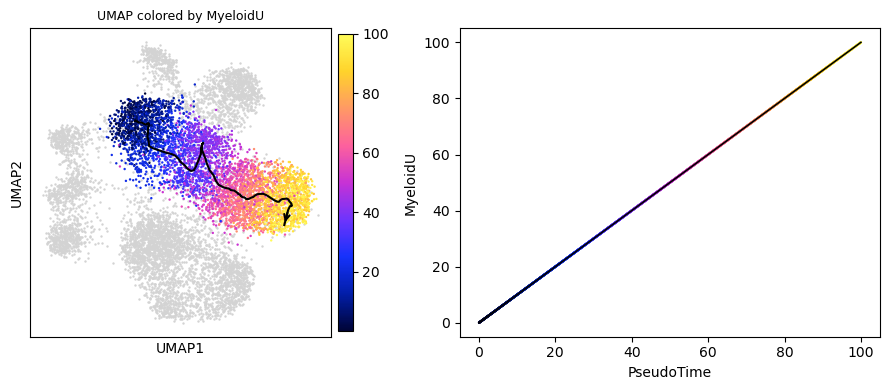

In [5]:
fig, axes = epi.pl.plot_trajectory(adata, trajectory_key='MyeloidU', basis='X_umap', show=False)
plt.show()

Colouring by a gene follows ArchR exactly: the values are clipped to their
1–99 % quantiles and transformed with `log2(x + 1)`. ArchR also smooths gene
scores with MAGIC weights (`getImputeWeights`). Epione accepts the same
cell × cell weights through `impute_weights=`; here we plot raw scores.

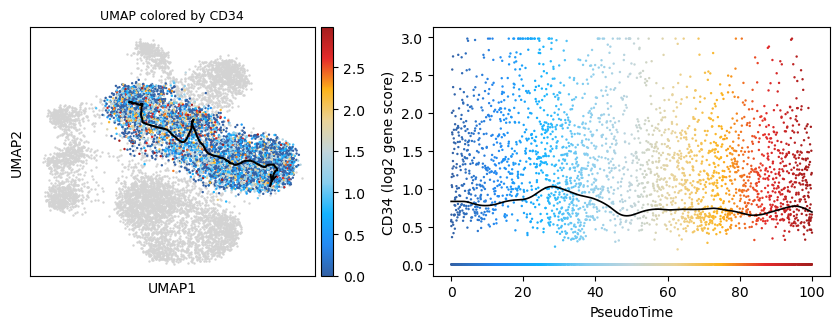

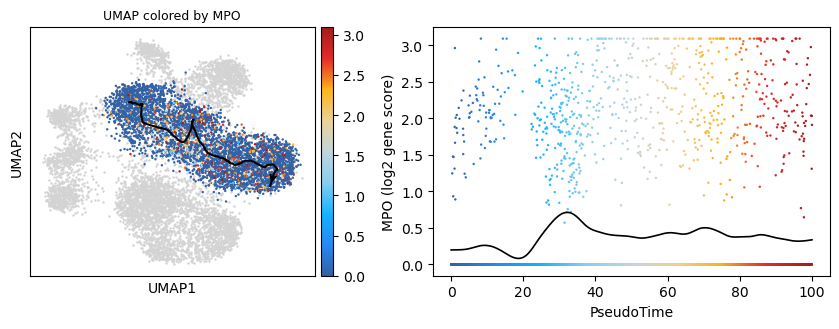

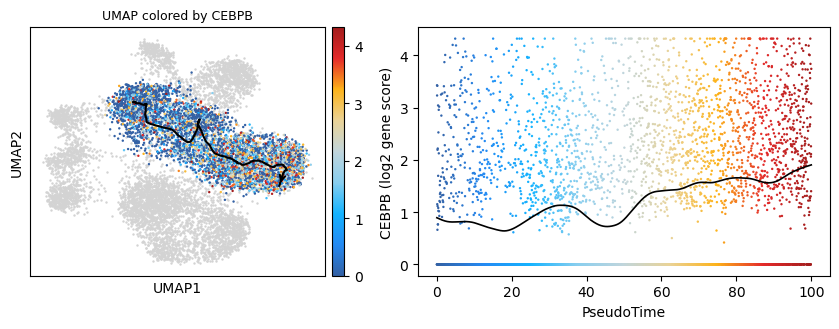

In [6]:
for g in ['CD34', 'MPO', 'CEBPB']:
    fig, axes = epi.pl.plot_trajectory(adata, trajectory_key='MyeloidU', color_by=g,
                                       basis='X_umap', figsize=(8.5, 3.4), show=False)
    axes[1].set_ylabel(f'{g} (log2 gene score)')
    plt.show()

## `get_trajectory` + `plot_trajectory_heatmap`

`get_trajectory` sums cells into 100 pseudo-time bins, normalises each bin to
10,000, applies `log2(x + 1)` and smooths with an 11-bin centred rolling mean.
The heatmap keeps the top 10 % most variable features, z-scores each row and
orders rows by the bin where they peak. Gene-score heatmaps use ArchR's
`blueYellow` palette.

In [7]:
%%time
trajGSM = epi.tl.get_trajectory(adata, 'MyeloidU', trajectory_label='Clusters', matrix_name='GeneScoreMatrix')
trajGSM

CPU times: user 447 ms, sys: 154 ms, total: 601 ms
Wall time: 602 ms


AnnData object with n_obs × n_vars = 100 × 20057
    obs: 'label'
    var: 'chrom', 'start', 'end', 'strand', 'name'
    uns: 'trajectory_params'
    layers: 'mat', 'smoothMat'

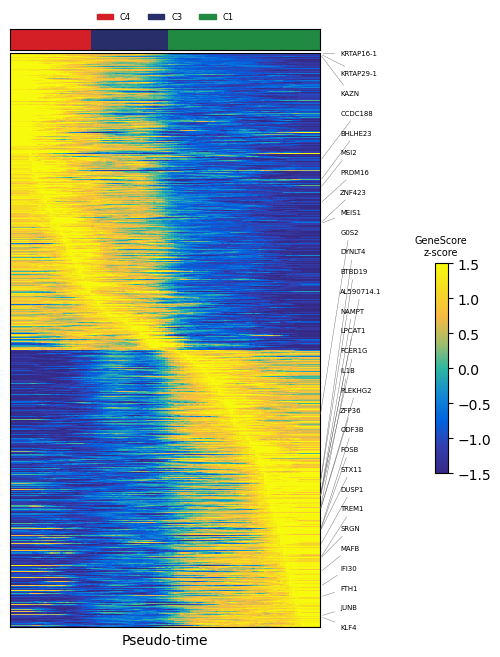

(2005, 100)


In [8]:
fig, mat = epi.pl.plot_trajectory_heatmap(trajGSM, var_cutoff=0.9, label_top=30, color_columns=True,
                                          title='GeneScore\nz-score', show=False)
plt.show()
print(mat.shape)

### TF activity trajectory

Per-cell TF activity comes from Epione's default `epi.tl.tf_activity` on the peak matrix
(`heme_peaks.h5ad`, JASPAR2020 motif matrix in `varm['motif']`): a conditional count model on
GC x accessibility bias strata, reporting a shrunken log fold change per cell and motif. We
learn the peak sensitivities within each sample (`groupby='Sample'`). Activities are not
counts, so set `log2_norm=False, scale_to=None`. Motifs are named `<JASPAR ID>_<TF>`; we
rename them ArchR-style (`TF_ID`) so that `correlate_trajectories` can match them to gene
names. (The chromVAR Z-scores of `epi.tl.compute_deviations` are also stored in the file, in
`obsm['motif_deviations']`, and can be used the same way.)

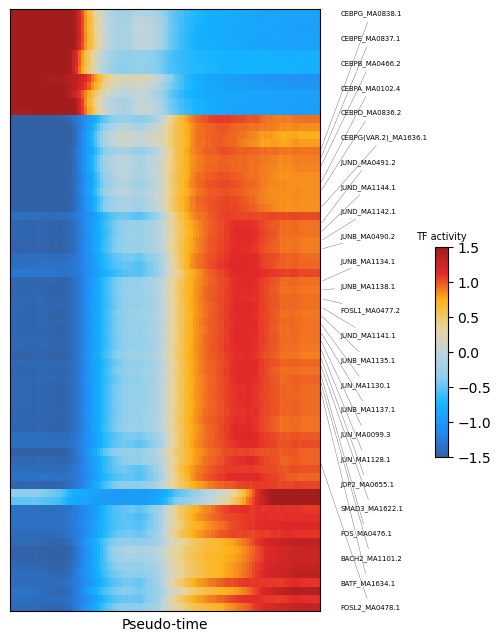

CPU times: user 1min 47s, sys: 3.69 s, total: 1min 50s
Wall time: 35.8 s


In [9]:
%%time
peaks = ad.read_h5ad(DATA / 'heme_peaks.h5ad')
epi.tl.tf_activity(peaks, groupby='Sample', verbose=False)      # default TF activity -> obsm['tf_activity']
motif_names = np.asarray(peaks.uns['tf_activity_names']).astype(str)
tf = [f"{m.split('_', 1)[1].upper()}_{m.split('_', 1)[0]}" for m in motif_names]
pos = peaks.obs_names.get_indexer(adata.obs_names)
assert (pos >= 0).all()
act = pd.DataFrame(np.asarray(peaks.obsm['tf_activity'])[pos], index=adata.obs_names, columns=tf)
del peaks
adata.obsm['MotifMatrix'] = act.add_prefix('activity:')

trajMM = epi.tl.get_trajectory(adata, 'MyeloidU', use_rep='MotifMatrix', log2_norm=False, scale_to=None,
                               matrix_name='MotifMatrix')
trajMM.var['name'] = [v.split(':', 1)[1] for v in trajMM.var_names]
fig, mat = epi.pl.plot_trajectory_heatmap(trajMM, var_cutoff=0.9, label_top=25, title='TF activity', show=False)
plt.show()

## `correlate_trajectories`: TF activity vs gene score

Features are paired by name after removing the `_…` / `-…` suffixes (`CEBPB_MA0466.2`
→ `CEBPB`). Pearson correlation is computed on the **unsmoothed** binned matrices.
Pairs with r > 0.5 whose variance is in the top 20 % of both trajectories are kept.

In [10]:
trajGSM.var['name'] = trajGSM.var['name'].astype(str)
cor = epi.tl.correlate_trajectories(trajGSM, trajMM, name_key1='name', name_key2='name')
pf = cor['correlatedMappings'].sort_values('Correlation', ascending=False)
print(len(cor['allMappings']), 'name-matched pairs;', len(pf), 'correlated')
pf[['matchname1', 'name2', 'Correlation', 'VarAssay1', 'VarAssay2', 'FDR']].head(15)

685 name-matched pairs; 15 correlated


,matchname1,name2,Correlation,VarAssay1,VarAssay2,FDR
14,NFIL3,activity:NFIL3_MA0025.2,0.826085,0.991175,0.957105,8.625393e-24
7,NR4A2,activity:NR4A2_MA0160.1,0.807378,0.993070,0.887399,3.975036e-22
4,FOS,activity:FOS_MA0476.1,0.789836,0.996959,0.970509,1.545055e-20
8,CEBPB,activity:CEBPB_MA0466.2,0.748048,0.997906,0.997319,1.726782e-17
1,ATF3,activity:ATF3_MA0605.2,0.746860,0.983547,0.895442,1.858567e-17
3,NFKB2,activity:NFKB2_MA0778.1,0.744498,0.991075,0.879357,2.597126e-17
2,GATA3,activity:GATA3_MA0037.3,0.739570,0.852321,0.945040,5.033808e-17
5,JUNB,activity:JUNB_MA0490.2,0.714083,0.999751,0.974531,2.211280e-15
9,BACH1,activity:BACH1_MA1633.1,0.692890,0.931146,0.955764,3.153188e-14
12,CEBPD,activity:CEBPD_MA0836.2,0.686855,0.995263,0.994638,6.296846e-14


ArchR's integrative heatmap: for each correlated pair, sum the row z-scores of
the gene score and the motif, order rows on that combined matrix, then draw both
heatmaps in the same row order.

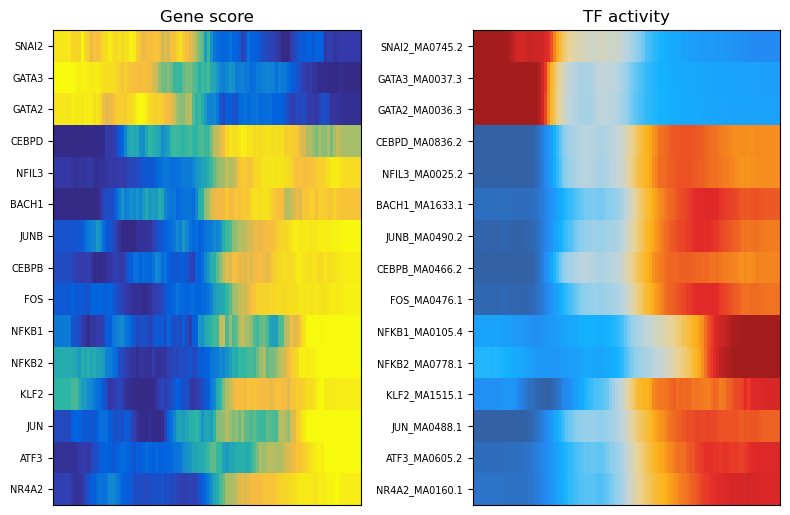

In [11]:
pairs = pf[pf['name2'].str.startswith('activity:')].drop_duplicates('name1').drop_duplicates('name2')
g2 = trajGSM[:, pairs['name1'].values].copy()
m2 = trajMM[:, pairs['name2'].values].copy()
zs = lambda a: (a - a.mean(0)) / a.std(0, ddof=1)
comb = g2.copy(); comb.layers['smoothMat'] = zs(g2.layers['smoothMat']) + zs(m2.layers['smoothMat'])
order = epi.tl.trajectory_heatmap_matrix(comb, var_cutoff=0).index
row_order = [list(g2.var_names).index(n) for n in order]
hg = epi.tl.trajectory_heatmap_matrix(g2, row_order=row_order)
hm = epi.tl.trajectory_heatmap_matrix(m2, row_order=row_order)

from epione.pl._trajectory import _archr_cmap
fig, axes = plt.subplots(1, 2, figsize=(8, 0.25 * len(hg) + 1.5))
for ax, h, cm, t in ((axes[0], hg, 'blueYellow', 'Gene score'), (axes[1], hm, 'solarExtra', 'TF activity')):
    ax.imshow(h.values, aspect='auto', cmap=_archr_cmap(cm), vmin=-1.5, vmax=1.5, interpolation='nearest')
    ax.set_title(t); ax.set_xticks([])
    ax.set_yticks(range(len(h))); ax.set_yticklabels([n.split(':')[-1] for n in h.index], fontsize=7)
plt.tight_layout(); plt.show()

## Parity vs ArchR

The port was validated against ArchR 1.0.3 on the ArchR-built version of this dataset
(10,660 cells, ArchR's own IterativeLSI, UMAP, `GeneScoreMatrix` and chromVAR `MotifMatrix`),
with the trajectory `C11 → C10 → C5` (progenitor → GMP → monocyte). The ArchR reference
outputs are generated outside this repository. All ported code paths are deterministic, so every
gate is class 1 (max |Δ| ≤ 1e-8) or exact for discrete outputs. Gates were fixed before the first
comparison in `tests/parity/trajectory/MANIFEST.md`; `tests/test_trajectory.py` re-runs the check
when `EPIONE_ARCHR_PARITY_DIR` points to the reference outputs. All 57 checks pass:

| Output | Class | Threshold | Value |
|---|---|---|---|
| initial alignment time | 1 | 1e-8 | 0 |
| `smooth.spline` fitted curve (LSI / UMAP) | 1 | 1e-8 | 8.4e-11 / 1.7e-10 |
| kNN indices, retained cells | exact | identical | identical |
| `Distance` / `DistanceIdx` | 1 | 1e-8 | 1.8e-10 / 9.1e-13 |
| pseudo-time (LSI, UMAP, `useAll = TRUE`) | 1 | 1e-8 | 2.8e-14 |
| `getTrajectory` binned + smoothed matrices (gene score, motif, `groupEvery = 2`) | 1 | 1e-8 | ≤ 1.7e-13 |
| bin labels | exact | identical | identical |
| heatmap matrix (`returnMatrix = TRUE`), 3 configurations | exact rows, class-1 values | 1e-8 | rows identical, ≤ 6.9e-15 |
| `correlateTrajectories` statistics (r, variances, t, p, FDR) | 1 | 1e-8 | ≤ 2.7e-14 |
| `correlateTrajectories` correlated pairs (33) | exact | identical | identical |
| `plotTrajectory` arrow path and scatter data | 1 | 1e-8 | ≤ 2.8e-14 |

R's `smooth.spline` is re-implemented in Python, including its `.3330` integration constant;
that is where the ~1e-10 spline differences come from.

### Notes

* ArchR passes both `df = 250` and `spar = 1` to `smooth.spline`. R ignores
  `df` when `spar` is given, so Epione only exposes `spar`.
* `epi.pl.plot_trajectory` draws its panel-2 trend with the ported smoothing
  spline. ArchR's trend line is `ggplot2::geom_smooth` (an mgcv GAM), which is
  only visual and is not parity-gated.
* `addSlingShotTrajectories` / `addMonocleTrajectory` (wrappers around the R
  packages) are not ported here.